# Import everything necessary for the project

In [1364]:
from ultralytics import YOLO 
import cv2 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import math

# Load the pretrained model
This model was pretrained by me using 299 images of 3D rendered coils with copper colored return bends. While this model does work on actual pictures of coils (shown below) it does need tweaking before being production ready.

In [1365]:
model = YOLO('/Users/keagonbeatty/Downloads/yolo-retry/runs/obb/train/weights/best.pt')

# Define necessary variables
This code defines all pre-detection variables needed to make the model work. these pre-detection variables are as follows:

-The image path of the image you will be makinf predictions on

-pattern_3_circuitry_string - the circuitry string of the coil you are inspecting

-x_rows - the number of rows in the x direction (up/down)

-y_rows - the number of rows in the y direction (left/right)

In [1366]:
image_path2 = "/Users/keagonbeatty/Documents/MachineLearning/pattern_pictures/3/rendered_image_91_90_3.png"
image_path = "/Users/keagonbeatty/Documents/MachineLearning/coil_real_pictures/IMG_7041.jpeg"
pattern_3_circuitry_string = '{{{2,3},{2,1}},{{2,7},{2,5}},{{5,8},{4,7}},{{1,4},{1,2}},{{4,5},{3,4}},{{4,3},{5,2}},{{3,2},{4,1}},{{1,8},{1,6}},{{3,8},{3,6}},{{5,6},{5,4}}}'
x_rows = 7
y_rows = 11

# Use the YOLO OBB model to predict return bend location

In [1367]:
#open the image
image = Image.open(image_path)

#use the pretrined Ultralytics YOLO OBB model to run inference (prediction) with a confidence score of 25% (low because it is a real image)
results = model.predict(image_path, conf=0.25)

"""
results are provided in a multitude of ways. I have found that for this application 
xywhr coordinates work the best
- x - the x coordinate of the center of the bounding box
- y - the y coordinate of the center of the bounding box
- w - the width of the bounding box
- h - the height of the bounding box
- r - the rotation in radians of the bounding box
"""
raw_predictions = results[0].obb.xywhr

"""
The predictions are saved as tensors, which is a special format used by tensorflow machine learning libraries.
In order to use these predictions we must turn them into a list so we can access properties of them
"""
predictions = []
for tens in raw_predictions:
    predictions.append(tens.tolist())



image 1/1 /Users/keagonbeatty/Documents/MachineLearning/coil_real_pictures/IMG_7041.jpeg: 640x640 227.2ms
Speed: 6.1ms preprocess, 227.2ms inference, 2.8ms postprocess per image at shape (1, 3, 640, 640)


# Clean up

In [1368]:
"""
because this model was not trained for real images it has one detection that is a false positive. 
For this demonstration we will remove this prediction
"""
predictions.pop(17)

[41.72972106933594,
 245.4844970703125,
 252.93931579589844,
 93.19865417480469,
 1.566874384880066]

In [1369]:
#view our list of predictions
print(predictions)

[[846.3761596679688, 1846.998779296875, 673.2166748046875, 279.4049987792969, 2.6465983390808105], [2356.181396484375, 2127.73291015625, 724.07666015625, 287.4801940917969, 0.5653173327445984], [476.69873046875, 2293.776123046875, 705.1691284179688, 294.4610290527344, 0.426626056432724], [2361.061767578125, 1203.79638671875, 710.3282470703125, 279.06915283203125, 0.506706714630127], [1945.8817138671875, 2347.809326171875, 704.0587768554688, 281.4560546875, 0.594804048538208], [1202.2042236328125, 2328.16357421875, 718.4592895507812, 284.04443359375, 0.4774923622608185], [2365.830810546875, 1664.109130859375, 732.7960815429688, 285.741943359375, 0.5389090776443481], [1202.300537109375, 287.2733154296875, 729.592041015625, 309.3156433105469, 2.617260456085205], [2387.78369140625, 736.2455444335938, 715.8211669921875, 306.1630554199219, 0.5122639536857605], [609.54541015625, 454.3580322265625, 700.2764282226562, 289.4457092285156, 1.384450078010559], [1775.1787109375, 1536.772216796875, 6

# Visualize the results

/var/folders/4y/c1fxwf455kl9km4k0t93jjr40000gn/T/ipykernel_97003/494715116.py:27: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)


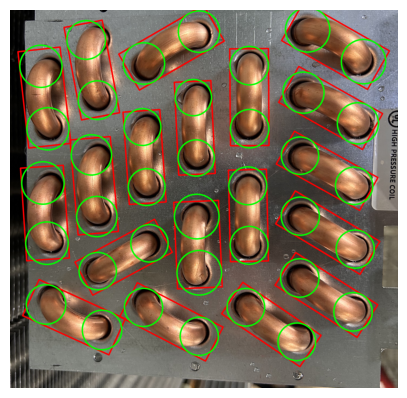

In [1370]:

#Read the image using cv2 library
image = cv2.imread(image_path)
#convert that image using color
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

#Create an empty array for the cv2 circles on the coil
circles = []

#using a ranged for loop so I can keep track of the index(lists are 0 indexing)
for i in range(1, len(predictions) + 1):

    #Access the prediciton (lists 0 indexing)
    pred = predictions[i-1]

    #create variables from prediction list (xywhr format)
    x_center, y_center, width, height, angle = pred

    #find the angle of rotation from the rotation value(it is in radians)
    angle_degrees = angle * 180 / np.pi
    
    #create a rect + boxpoints variable which holds the cv2 polylines coordinate for the rectangle
    rect = ((x_center, y_center), (width, height), angle_degrees)

    box_points = cv2.boxPoints(rect)

    #convert all to ints because measurement it pixel based (cant have fractional pixels)
    box_points = np.int0(box_points)

    #add the prediction boxes to the image (red boxes)
    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=10)

    #from info provided by prediction and some math find the offset for the circle coordinates
    add_circles1 = [int(x_center + (np.cos(angle) * ((width * .65) / 2))), 
                    int(y_center + (np.sin(angle) * ((width * .65) / 2))), int(height / 2), i]
    add_circles2 = [int(x_center - (np.cos(angle) * ((width * .65) / 2))), 
                    int(y_center - (np.sin(angle) * ((width * .65) / 2))), int(height / 2), i]
    
    #add the circles to the image
    cv2.circle(image, (add_circles1[0], 
                       add_circles1[1]), add_circles1[2], (0, 255, 0), thickness=10)
    cv2.circle(image, (add_circles2[0], 
                       add_circles2[1]), add_circles2[2], (0, 255, 0), thickness=10)
    
    #append the circles to the circles list so we can use pandas for data analysis
    circles.append(add_circles1)
    circles.append(add_circles2)

#show the figure
plt.figure(figsize=(5,5))
plt.imshow(image)
plt.axis("off")
plt.show()


# Run some analysis on the coordinates

In [1371]:
#Save the coordinates as a pandas dataframe for ease of use
coordinates = pd.DataFrame(circles, columns=['X', 'Y', 'Radius', 'return_bend'])

In [1372]:
#Create divisions, which are used to seperate bounding box coordinates into their respective circuitry X & Y coordinates
divisions = (coordinates['X'].max() - coordinates['X'].min())/x_rows

# Visualize the results - showing grid layout

In [1373]:
"""
x_groups and y_groups are a measurement used to classify where a set of coordinates are relative to their grid lines.
They care calculated by taking the maximum and minimum x and y coordinates and subtracting them from each other (m_max - x_min)
which results in the total space between recognized features. Because coils have rows and columns these measurements should be either
recieved by the model, (x_rows = coils_rows) (y_rows = fin height - single_progression_extrusion). These values are then subtracted
by one in order 
"""

x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)
x_inter_group_space = x_groups * .45

y_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)
y_inter_group_space = y_groups * .45

print(x_groups)
print(y_groups)

400.3333333333333
232.1


length of circles array: 38


/var/folders/4y/c1fxwf455kl9km4k0t93jjr40000gn/T/ipykernel_97003/1805079517.py:18: DeprecationWarning: `np.int0` is a deprecated alias for `np.intp`.  (Deprecated NumPy 1.24)
  box_points = np.int0(box_points)


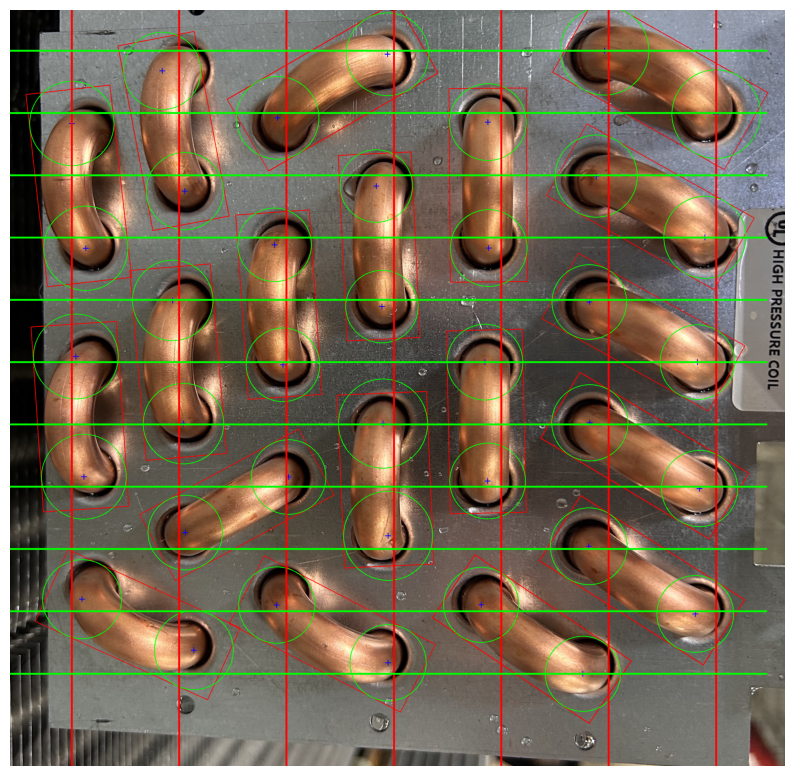

In [1374]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi

    rect = ((x_center, y_center), (width, height), angle_degrees)

    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)

    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    circ_x =(np.cos(pred[4]) * ((width * .65) / 2))
    circ_y =(np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)


for circle in circles:
    cv2.line(image, (circle[0], circle[1]-10), (circle[0], circle[1]+10), color=(0, 0, 255), thickness = 2)
    cv2.line(image, (circle[0]-10, circle[1]), (circle[0]+10, circle[1]), color=(0, 0, 255), thickness = 2)

for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    cv2.line(image, (y_coord, 0), (y_coord, image.shape[1]), color=(255, 0, 0), thickness=5)

for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    cv2.line(image, (0, x_coord), (image.shape[0], x_coord), color=(0, 255, 0), thickness=5)

print(f'length of circles array: {len(circles)}')
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()

In [1375]:
"""x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)
x_inter_group_space = x_groups * .45

y_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)
y_inter_group_space = y_groups * .45

print(x_groups)
print(y_groups)"""

"x_groups = (coordinates['X'].max() - coordinates['X'].min()) / (x_rows-1)\nx_inter_group_space = x_groups * .45\n\ny_groups = (coordinates['Y'].max() - coordinates['Y'].min()) / (y_rows - 1)\ny_inter_group_space = y_groups * .45\n\nprint(x_groups)\nprint(y_groups)"

In [1376]:
"""import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

for pred in predictions:
    x_center, y_center, width, height, angle = pred
    angle_degrees = angle * 180 / np.pi

    rect = ((x_center, y_center), (width, height), angle_degrees)

    box_points = cv2.boxPoints(rect)
    box_points = np.int0(box_points)

    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)

    circ_x = (np.cos(pred[4]) * ((width * .65) / 2))
    circ_y = (np.sin(pred[4]) * ((width * .65) / 2))
    radius = int(height / 2)
    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)
    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)


for circle in circles:
    cv2.line(image, (circle[0], circle[1] - 10), (circle[0], circle[1] + 10), color=(0, 0, 255), thickness=2)
    cv2.line(image, (circle[0] - 10, circle[1]), (circle[0] + 10, circle[1]), color=(0, 0, 255), thickness=2)

for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    cv2.line(image, (y_coord, 0), (y_coord, image.shape[1]), color=(255, 0, 0), thickness=2)

for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    cv2.line(image, (0, x_coord), (image.shape[0], x_coord), color=(0, 255, 0), thickness=2)

plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("off")
plt.show()"""


'import cv2\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom PIL import Image\n\nimage = cv2.imread(image_path)\nif image is None:\n    raise ValueError("Image not loaded. Check the image path.")\nimage = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)\n\nfor pred in predictions:\n    x_center, y_center, width, height, angle = pred\n    angle_degrees = angle * 180 / np.pi\n\n    rect = ((x_center, y_center), (width, height), angle_degrees)\n\n    box_points = cv2.boxPoints(rect)\n    box_points = np.int0(box_points)\n\n    cv2.polylines(image, [box_points], isClosed=True, color=(255, 0, 0), thickness=2)\n\n    circ_x = (np.cos(pred[4]) * ((width * .65) / 2))\n    circ_y = (np.sin(pred[4]) * ((width * .65) / 2))\n    radius = int(height / 2)\n    cv2.circle(image, (int(x_center + circ_x), int(y_center + circ_y)), radius, (0, 255, 0), thickness=2)\n    cv2.circle(image, (int(x_center - circ_x), int(y_center - circ_y)), radius, (0, 255, 0), thickness=2)\n\n\nfor circle in circles:\n    c

In [1377]:

x_group_list=[]
for i in range(0, x_rows):
    y_coord = int(coordinates['X'].min() + (x_groups * i))
    x_group_list.append((y_coord - x_inter_group_space, y_coord + x_inter_group_space))

y_group_list=[]
for i in range(0, y_rows):
    x_coord = int(coordinates['Y'].min() + (y_groups * i))
    y_group_list.append((x_coord - y_inter_group_space, x_coord + y_inter_group_space))
    

In [1378]:

def assign_group_x(x):
    for i, (min_val, max_val) in enumerate(x_group_list):
        if min_val <= x < max_val:
            return i
    return len(x_group_list)

def assign_group_y(y):
    for i, (min_val, max_val) in enumerate(y_group_list):
        if min_val <= y < max_val:
            return i
    return len(y_group_list)


In [1379]:

coordinates['Group_X'] = coordinates['X'].apply(assign_group_x)
coordinates['Group_Y'] = coordinates['Y'].apply(assign_group_y)

In [1380]:
grouped = coordinates.groupby('return_bend')[['Group_X', 'Group_Y']]

result = '{' + ','.join(
    '{{{}}}'.format(
        ','.join('{{{},{}}}'.format(row['Group_X']+ 1, row['Group_Y'] + 1) for _, row in group.iterrows())
    )
    for _, group in grouped
) + '}'

print(result)


{{{2,9},{3,8}},{{7,10},{6,9}},{{2,11},{1,10}},{{7,6},{6,5}},{{6,11},{5,10}},{{4,11},{3,10}},{{7,8},{6,7}},{{3,2},{4,1}},{{7,4},{6,3}},{{2,3},{2,1}},{{5,8},{5,6}},{{5,4},{5,2}},{{4,9},{4,7}},{{3,6},{3,4}},{{4,5},{4,3}},{{1,8},{1,6}},{{1,4},{1,2}},{{2,7},{2,5}},{{7,2},{6,1}}}


In [1381]:
print(pattern_3_circuitry_string == result)

False


In [1382]:
import ast

transformed_result = result.replace('{', '[').replace('}', ']')
transformed_input = pattern_3_circuitry_string.replace('{', '[').replace('}', ']')

list_of_lists_result = ast.literal_eval(transformed_result)
list_of_lists_input = ast.literal_eval(transformed_input)

#print(list_of_lists_result == list_of_lists_input)
print(list_of_lists_result)


[[[2, 9], [3, 8]], [[7, 10], [6, 9]], [[2, 11], [1, 10]], [[7, 6], [6, 5]], [[6, 11], [5, 10]], [[4, 11], [3, 10]], [[7, 8], [6, 7]], [[3, 2], [4, 1]], [[7, 4], [6, 3]], [[2, 3], [2, 1]], [[5, 8], [5, 6]], [[5, 4], [5, 2]], [[4, 9], [4, 7]], [[3, 6], [3, 4]], [[4, 5], [4, 3]], [[1, 8], [1, 6]], [[1, 4], [1, 2]], [[2, 7], [2, 5]], [[7, 2], [6, 1]]]


In [1383]:
print(coordinates.sort_values(by='return_bend'))

       X     Y  Radius  return_bend  Group_X  Group_Y
0    653  1950     139            1        1        8
1   1038  1743     139            1        2        7
2   2554  2253     143            2        6        9
3   2157  2001     143            2        5        8
4    685  2388     147            3        1       10
5    268  2198     147            3        0        9
6   2562  1315     139            4        6        5
7   2159  1091     139            4        5        4
9   1756  2219     140            5        4        9
8   2135  2476     140            5        5       10
10  1409  2435     142            6        3       10
11   994  2220     142            6        2        9
12  2570  1786     142            7        6        7
13  2161  1541     142            7        5        6
14   997   405     154            8        2        1
15  1407   168     154            8        3        0
17  2185   622     153            9        5        2
16  2590   850     153      

In [1384]:
radius = coordinates['Radius'].mean()

In [1385]:
pattern_coordinates = coordinates.drop(labels=['Radius', 'return_bend'], axis=1)

In [1386]:
print(pattern_coordinates)

       X     Y  Group_X  Group_Y
0    653  1950        1        8
1   1038  1743        2        7
2   2554  2253        6        9
3   2157  2001        5        8
4    685  2388        1       10
5    268  2198        0        9
6   2562  1315        6        5
7   2159  1091        5        4
8   2135  2476        5       10
9   1756  2219        4        9
10  1409  2435        3       10
11   994  2220        2        9
12  2570  1786        6        7
13  2161  1541        5        6
14   997   405        2        1
15  1407   168        3        0
16  2590   850        6        3
17  2185   622        5        2
18   651   678        1        2
19   567   230        1        0
20  1780  1758        4        7
21  1770  1315        4        5
22  1784   890        4        3
23  1781   421        4        1
24  1409  1962        3        8
25  1390  1544        3        6
26  1017  1325        2        5
27   986   878        2        3
28  1386  1108        3        4
29  1365  

In [1387]:
def compare_lists(result_list, input_list):
    correct_return_bends = []
    incorrect_return_bends = []
    not_found_return_bends = []

    result_list_sorted = [sorted(map(tuple, sublist)) for sublist in result_list]
    input_list_sorted = [sorted(map(tuple, sublist)) for sublist in input_list]
    matched_input = set()

    for res in result_list_sorted:
        if res in input_list_sorted:
            correct_return_bends.append(res)
            matched_input.add(tuple(map(tuple, res)))
        else:
            incorrect_return_bends.append(res)

    for inp in input_list_sorted:
        if tuple(map(tuple, inp)) not in matched_input:
            not_found_return_bends.append(inp)

    return correct_return_bends, incorrect_return_bends, not_found_return_bends

correct, incorrect, not_found = compare_lists(list_of_lists_result, list_of_lists_input)

print("Correct Return Bends:", correct)
print("Incorrect Return Bends:", incorrect)
print("Not Found Return Bends:", not_found)

results_array = [(correct, (100, 100, 255)), (incorrect, (255, 0, 0)), (not_found, (255,255,0))]


Correct Return Bends: [[(3, 2), (4, 1)], [(2, 1), (2, 3)], [(1, 6), (1, 8)], [(1, 2), (1, 4)], [(2, 5), (2, 7)]]
Incorrect Return Bends: [[(2, 9), (3, 8)], [(6, 9), (7, 10)], [(1, 10), (2, 11)], [(6, 5), (7, 6)], [(5, 10), (6, 11)], [(3, 10), (4, 11)], [(6, 7), (7, 8)], [(6, 3), (7, 4)], [(5, 6), (5, 8)], [(5, 2), (5, 4)], [(4, 7), (4, 9)], [(3, 4), (3, 6)], [(4, 3), (4, 5)], [(6, 1), (7, 2)]]
Not Found Return Bends: [[(4, 7), (5, 8)], [(3, 4), (4, 5)], [(4, 3), (5, 2)], [(3, 6), (3, 8)], [(5, 4), (5, 6)]]


In [1388]:
#Test to see how to filter column values in pandas
filtered_df = pattern_coordinates[(pattern_coordinates['Group_X'] == 4) & (pattern_coordinates['Group_Y'] == 3)]

x_values = filtered_df['X'].tolist()
y_values = filtered_df['Y'].tolist()

print("X values:", x_values)
print("Y values:", y_values)

X values: [1784]
Y values: [890]


In [1389]:
pattern_coordinates['Group_X'] = pattern_coordinates['Group_X'] + 1
pattern_coordinates['Group_Y'] = pattern_coordinates['Group_Y'] + 1



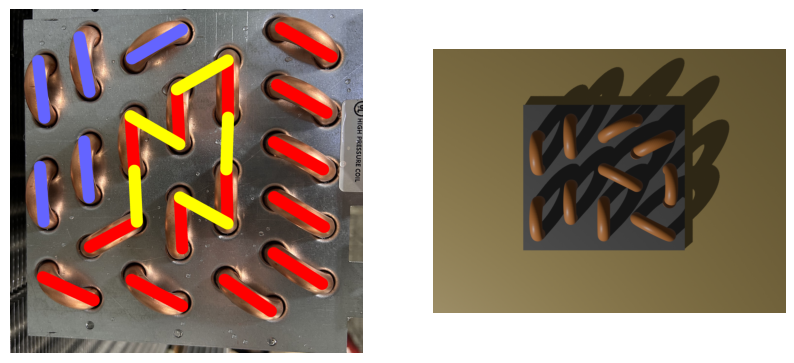

In [1390]:
import cv2
import pandas as pd
import matplotlib.pyplot as plt
image_other = cv2.imread(image_path2)
image = cv2.imread(image_path)
if image is None:
    raise ValueError("Image not loaded. Check the image path.")
if image_other is None:
    raise ValueError("Image not loaded. Check the image path.")
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
image_other = cv2.cvtColor(image_other, cv2.COLOR_BGR2RGB)

for result in results_array:
    for res in result[0]:
        pattern_1_x = res[0][0]
        pattern_1_y = res[0][1]
        pattern_2_x = res[1][0]
        pattern_2_y = res[1][1]

        filtered_df_1 = pattern_coordinates[(pattern_coordinates['Group_X'] == pattern_1_x) & (pattern_coordinates['Group_Y'] == pattern_1_y)]
        filtered_df_2 = pattern_coordinates[(pattern_coordinates['Group_X'] == pattern_2_x) & (pattern_coordinates['Group_Y'] == pattern_2_y)]
        x_values_1 = int(filtered_df_1['X'].values[0])
        y_values_1 = int(filtered_df_1['Y'].values[0])
        x_values_2 = int(filtered_df_2['X'].values[0])
        y_values_2 = int(filtered_df_2['Y'].values[0])

        cv2.line(image, (x_values_1, y_values_1), (x_values_2, y_values_2), color=result[1], thickness=int(radius-50))

fig, axs = plt.subplots(1, 2, figsize=(10, 12))

# Show the first image
axs[0].imshow(image)
axs[0].axis("off")

# Show the second image
axs[1].imshow(image_other)
axs[1].axis("off")

# Display the images
plt.show()
